# Phase 2: Exploratory Data Analysis (EDA) - Sample Superstore Dataset

**Project:** Sales Data Analysis & Business Intelligence Dashboard  
**Phase:** 2 - Data Acquisition & Exploratory Data Analysis (EDA)  
**Author:** Senior Data Analyst & Python Developer  

### Objectives:
1. Inspect dataset structure, schema, and column data types without modifying raw files.
2. Evaluate data hygiene: audit missing values, null counts, and duplicate records.
3. Generate comprehensive descriptive statistics for sales, profit, quantity, and discount metrics.
4. Uncover commercial performance patterns: product revenue leaders, category contributions, and regional variance.
5. Analyze multi-year temporal trends and seasonality.
6. Identify statistical outliers using the Interquartile Range (IQR) method.
7. Construct publication-quality visualizations using Matplotlib and Seaborn.


In [1]:
# ==========================================
# 1. Environment & Library Initialization
# ==========================================
import os
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')

# Set plotting styles and aesthetic configurations
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11

# Ensure reports directory exists for exported visualizations
reports_dir = Path('../reports') if Path('../reports').resolve().parent.name == 'Sales-Analytics-Project' else Path('reports')
reports_dir.mkdir(parents=True, exist_ok=True)

print("Environment configured successfully. Ready for EDA.")


Environment configured successfully. Ready for EDA.


## 2. Dataset Discovery & Loading
Inspecting and loading the raw dataset from `data/raw/Sample - Superstore.csv`.  
*Note:* The file uses `windows-1252` encoding to support special characters (such as European umlauts in customer and product names).


In [2]:
# Define path to raw dataset with fallback for working directory
data_path = Path('../data/raw/Sample - Superstore.csv')
if not data_path.exists():
    data_path = Path('data/raw/Sample - Superstore.csv')

assert data_path.exists(), f"Error: Dataset not found at {data_path.resolve()}"

# Load raw dataset into pandas DataFrame
df = pd.read_csv(data_path, encoding='windows-1252')

print(f"Dataset successfully loaded from: {data_path.name}")
print(f"Resolved path: {data_path.resolve()}")


Dataset successfully loaded from: Sample - Superstore.csv
Resolved path: D:\one drive\OneDrive\Desktop\Sales-Analytics-Project\data\raw\Sample - Superstore.csv


## 3. First 10 Rows of the Dataset
Displaying the initial 10 records to examine tabular structure and sample values.


In [3]:
# Display first 10 rows
df.head(10)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164
5,6,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7,0.00,14.1694
6,7,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,OFF-AR-10002833,Office Supplies,Art,Newell 322,7.2800,4,0.00,1.9656
7,8,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,TEC-PH-10002275,Technology,Phones,Mitel 5320 IP Phone VoIP phone,907.1520,6,0.20,90.7152
8,9,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,OFF-BI-10003910,Office Supplies,Binders,DXL Angle-View Binders with Locking Rings by S...,18.5040,3,0.20,5.7825
9,10,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,OFF-AP-10002892,Office Supplies,Appliances,Belkin F5C206VTEL 6 Outlet Surge,114.9000,5,0.00,34.4700


## 4. Dataset Dimensions & Structural Schema
Auditing the dimensions (rows and columns), column naming conventions, and native data types.


In [4]:
# Display total rows and columns
total_rows, total_cols = df.shape
print(f"Total Rows:    {total_rows:,}")
print(f"Total Columns: {total_cols}")

# Structural Schema Overview
schema_df = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': [str(t) for t in df.dtypes],
    'Non-Null Count': df.notnull().sum().values,
    'Null Count': df.isnull().sum().values,
    'Null %': ((df.isnull().sum().values / len(df)) * 100).round(2),
    'Sample Value': [str(df[col].iloc[0]) for col in df.columns]
})
schema_df


Total Rows:    9,994
Total Columns: 21


,Column Name,Data Type,Non-Null Count,Null Count,Null %,Sample Value
0,Row ID,int64,9994,0,0.0,1
1,Order ID,str,9994,0,0.0,CA-2016-152156
2,Order Date,str,9994,0,0.0,11/8/2016
3,Ship Date,str,9994,0,0.0,11/11/2016
4,Ship Mode,str,9994,0,0.0,Second Class
5,Customer ID,str,9994,0,0.0,CG-12520
6,Customer Name,str,9994,0,0.0,Claire Gute
7,Segment,str,9994,0,0.0,Consumer
8,Country,str,9994,0,0.0,United States
9,City,str,9994,0,0.0,Henderson


## 5. Data Quality Audit: Missing Values & Duplicates
Auditing data completeness across every column and evaluating duplicate records (full row matches vs. business duplicates).


In [5]:
# 1. Missing Values Analysis
missing_counts = df.isnull().sum()
total_missing = missing_counts.sum()
print(f"Total Missing Values Across Dataset: {total_missing}")
if total_missing == 0:
    print("-> DATASET COMPLETENESS: 100% complete. Zero null values detected.")
else:
    print(missing_counts[missing_counts > 0])

# 2. Duplicate Records Analysis
# Exact full row duplicates
full_dupes = df.duplicated().sum()
print(f"\nExact Full Row Duplicates (including 'Row ID'): {full_dupes}")

# Business duplicates (ignoring artificial surrogate 'Row ID')
business_dupes = df.drop(columns=['Row ID']).duplicated().sum()
print(f"Business Duplicate Records (ignoring 'Row ID'): {business_dupes}")

if business_dupes > 0:
    print("\nIdentified Duplicate Transaction Rows:")
    duplicate_rows = df[df.drop(columns=['Row ID']).duplicated(keep=False)]
    display(duplicate_rows[['Row ID', 'Order ID', 'Order Date', 'Customer ID', 'Customer Name', 'Product Name', 'Sales', 'Profit']])


Total Missing Values Across Dataset: 0
-> DATASET COMPLETENESS: 100% complete. Zero null values detected.

Exact Full Row Duplicates (including 'Row ID'): 0
Business Duplicate Records (ignoring 'Row ID'): 1

Identified Duplicate Transaction Rows:


,Row ID,Order ID,Order Date,Customer ID,Customer Name,Product Name,Sales,Profit
3405,3406,US-2014-150119,4/23/2014,LB-16795,Laurel Beltran,Global Leather Highback Executive Chair with P...,281.372,-12.0588
3406,3407,US-2014-150119,4/23/2014,LB-16795,Laurel Beltran,Global Leather Highback Executive Chair with P...,281.372,-12.0588


## 6. Descriptive Statistical Profiling
Computing central tendency, dispersion, skewness, and kurtosis across numerical columns: `Sales`, `Quantity`, `Discount`, and `Profit`.


In [6]:
# Summary statistics for numerical fields
num_cols = ['Sales', 'Quantity', 'Discount', 'Profit']

stats_df = df[num_cols].describe().T
stats_df['median'] = df[num_cols].median()
stats_df['variance'] = df[num_cols].var()
stats_df['skewness'] = df[num_cols].skew()
stats_df['kurtosis'] = df[num_cols].kurt()

# Reorder columns for optimal readability
stats_display = stats_df[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'skewness', 'kurtosis']]
stats_display


,count,mean,std,min,25%,median,75%,max,skewness,kurtosis
Sales,9994.0,229.858001,623.245101,0.444,17.28000,54.4900,209.940,22638.480,12.972752,305.311753
Quantity,9994.0,3.789574,2.225110,1.000,2.00000,3.0000,5.000,14.000,1.278545,1.991889
Discount,9994.0,0.156203,0.206452,0.000,0.00000,0.2000,0.200,0.800,1.684295,2.409546
Profit,9994.0,28.656896,234.260108,-6599.978,1.72875,8.6665,29.364,8399.976,7.561432,397.188515


## 7. Deep-Dive Commercial & Operational Analytics
Calculating enterprise retail KPIs, product leaders, categorical dynamics, and regional profitability.


In [7]:
# High-Level Commercial KPIs
total_revenue = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_qty = df['Quantity'].sum()
profit_margin = (total_profit / total_revenue) * 100
avg_order_val = df.groupby('Order ID')['Sales'].sum().mean()
loss_orders = df[df['Profit'] < 0]

print("==================================================")
print("             EXECUTIVE KPI SUMMARY                ")
print("==================================================")
print(f"Total Net Sales:          ${total_revenue:,.2f}")
print(f"Total Operating Profit:   ${total_profit:,.2f}")
print(f"Overall Profit Margin:    {profit_margin:.2f}%")
print(f"Total Units Sold:         {total_qty:,} units")
print(f"Average Order Value (AOV): ${avg_order_val:,.2f}")
print(f"Loss-Making Transactions: {len(loss_orders):,} ({len(loss_orders)/len(df)*100:.2f}% of orders)")
print(f"Total Unrecovered Losses: ${loss_orders['Profit'].sum():,.2f}")
print("==================================================")


             EXECUTIVE KPI SUMMARY                
Total Net Sales:          $2,297,200.86
Total Operating Profit:   $286,397.02
Overall Profit Margin:    12.47%
Total Units Sold:         37,873 units
Average Order Value (AOV): $458.61
Loss-Making Transactions: 1,871 (18.72% of orders)
Total Unrecovered Losses: $-156,131.29


In [8]:
# Top 10 Products by Total Sales
top10_products = df.groupby('Product Name').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Order_Frequency=('Order ID', 'count')
).sort_values(by='Total_Sales', ascending=False).head(10)

top10_products['Profit_Margin_%'] = ((top10_products['Total_Profit'] / top10_products['Total_Sales']) * 100).round(2)
top10_products['Revenue_Share_%'] = ((top10_products['Total_Sales'] / total_revenue) * 100).round(2)

print("Top 10 Revenue-Generating Products:")
top10_products


Top 10 Revenue-Generating Products:


,Total_Sales,Total_Profit,Units_Sold,Order_Frequency,Profit_Margin_%,Revenue_Share_%
Product Name,,,,,,
Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04,20,5,40.91,2.68
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7.753039e+03,31,10,28.24,1.20
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1.811078e+03,6,1,-8.00,0.99
HON 5400 Series Task Chairs for Big and Tall,21870.576,5.684342e-14,39,8,0.00,0.95
GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03,37,11,11.27,0.86
GBC Ibimaster 500 Manual ProClick Binding System,19024.500,7.609800e+02,48,9,4.00,0.83
Hewlett Packard LaserJet 3310 Copier,18839.686,6.983884e+03,38,8,37.07,0.82
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4.094977e+03,12,3,22.29,0.80
GBC DocuBind P400 Electric Binding System,17965.068,-1.878166e+03,27,6,-10.45,0.78


In [9]:
# Category-Level Performance
cat_summary = df.groupby('Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Units=('Quantity', 'sum'),
    Avg_Discount=('Discount', 'mean'),
    Order_Count=('Order ID', 'count')
)
cat_summary['Profit_Margin_%'] = ((cat_summary['Total_Profit'] / cat_summary['Total_Sales']) * 100).round(2)
cat_summary['Sales_Contribution_%'] = ((cat_summary['Total_Sales'] / total_revenue) * 100).round(2)

print("--- Category Performance Summary ---")
display(cat_summary)

# Sub-Category Level Performance
subcat_summary = df.groupby(['Category', 'Sub-Category']).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Avg_Discount=('Discount', 'mean')
).sort_values(by='Total_Sales', ascending=False)
subcat_summary['Profit_Margin_%'] = ((subcat_summary['Total_Profit'] / subcat_summary['Total_Sales']) * 100).round(2)

print("\n--- Sub-Category Performance (Ranked by Sales) ---")
display(subcat_summary)


--- Category Performance Summary ---


,Total_Sales,Total_Profit,Total_Units,Avg_Discount,Order_Count,Profit_Margin_%,Sales_Contribution_%
Category,,,,,,,
Furniture,741999.7953,18451.2728,8028,0.173923,2121,2.49,32.3
Office Supplies,719047.0320,122490.8008,22906,0.157285,6026,17.04,31.3
Technology,836154.0330,145454.9481,6939,0.132323,1847,17.40,36.4



--- Sub-Category Performance (Ranked by Sales) ---


Total_Sales  Total_Profit  Units_Sold  \
Category        Sub-Category                                          
Technology      Phones        330007.0540    44515.7306        3289   
Furniture       Chairs        328449.1030    26590.1663        2356   
Office Supplies Storage       223843.6080    21278.8264        3158   
Furniture       Tables        206965.5320   -17725.4811        1241   
Office Supplies Binders       203412.7330    30221.7633        5974   
Technology      Machines      189238.6310     3384.7569         440   
                Accessories   167380.3180    41936.6357        2976   
                Copiers       149528.0300    55617.8249         234   
Furniture       Bookcases     114879.9963    -3472.5560         868   
Office Supplies Appliances    107532.1610    18138.0054        1729   
Furniture       Furnishings    91705.1640    13059.1436        3563   
Office Supplies Paper          78479.2060    34053.5693        5178   
                Supplies       46673.5380    -1189.0995         647   
                Art            27118.7920     6527.7870        3000   
                Envelopes      16476.4020     6964.1767         906   
                Labels         12486.3120     5546.2540        1400   
                Fasteners       3024.2800      949.5182         914   

                              Avg_Discount  Profit_Margin_%  
Category        Sub-Category                                 
Technology      Phones            0.154556            13.49  
Furniture       Chairs            0.170178             8.10  
Office Supplies Storage           0.074704             9.51  
Furniture       Tables            0.261285            -8.56  
Office Supplies Binders           0.372292            14.86  
Technology      Machines          0.306087             1.79  
                Accessories       0.078452            25.05  
                Copiers           0.161765            37.20  
Furniture       Bookcases         0.211140            -3.02  
Office Supplies Appliances        0.166524            16.87  
Furniture       Furnishings       0.138349            14.24  
Office Supplies Paper             0.074891            43.39  
                Supplies          0.076842            -2.55  
                Art               0.074874            24.07  
                Envelopes         0.080315            42.27  
                Labels            0.068681            44.42  
                Fasteners         0.082028            31.40

In [10]:
# Regional Performance
region_summary = df.groupby('Region').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Units=('Quantity', 'sum'),
    Avg_Discount=('Discount', 'mean'),
    Unique_Customers=('Customer ID', 'nunique')
)
region_summary['Profit_Margin_%'] = ((region_summary['Total_Profit'] / region_summary['Total_Sales']) * 100).round(2)
region_summary['Sales_Share_%'] = ((region_summary['Total_Sales'] / total_revenue) * 100).round(2)

print("--- Regional Commercial Performance ---")
display(region_summary)

# Region by Category Matrix (Sales & Profit)
print("\n--- Sales Cross-Tabulation: Region by Category ($) ---")
display(df.pivot_table(index='Region', columns='Category', values='Sales', aggfunc='sum').round(2))

print("\n--- Profit Cross-Tabulation: Region by Category ($) ---")
display(df.pivot_table(index='Region', columns='Category', values='Profit', aggfunc='sum').round(2))


--- Regional Commercial Performance ---


,Total_Sales,Total_Profit,Total_Units,Avg_Discount,Unique_Customers,Profit_Margin_%,Sales_Share_%
Region,,,,,,,
Central,501239.8908,39706.3625,8780,0.240353,629,7.92,21.82
East,678781.2400,91522.7800,10618,0.145365,674,13.48,29.55
South,391721.9050,46749.4303,6209,0.147253,512,11.93,17.05
West,725457.8245,108418.4489,12266,0.109335,686,14.94,31.58



--- Sales Cross-Tabulation: Region by Category ($) ---


Category,Furniture,Office Supplies,Technology
Region,,,
Central,163797.16,167026.42,170416.31
East,208291.20,205516.06,264973.98
South,117298.68,125651.31,148771.91
West,252612.74,220853.25,251991.83



--- Profit Cross-Tabulation: Region by Category ($) ---


Category,Furniture,Office Supplies,Technology
Region,,,
Central,-2871.05,8879.98,33697.43
East,3046.17,41014.58,47462.04
South,6771.21,19986.39,19991.83
West,11504.95,52609.85,44303.65


In [11]:
# Monthly Sales and Profit Trend Analysis
# Create temporary time-series representation without altering the original df
df_temp = df.copy()
df_temp['Order Date'] = pd.to_datetime(df_temp['Order Date'])
df_temp['Year_Month'] = df_temp['Order Date'].dt.to_period('M')

monthly_trend = df_temp.groupby('Year_Month').agg(
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Orders=('Order ID', 'nunique'),
    Units=('Quantity', 'sum')
).reset_index()

monthly_trend['Year_Month_Str'] = monthly_trend['Year_Month'].astype(str)

print("--- Monthly Trend Overview (First 6 and Last 6 Months) ---")
display(pd.concat([monthly_trend.head(6), monthly_trend.tail(6)]).reset_index(drop=True))


--- Monthly Trend Overview (First 6 and Last 6 Months) ---


,Year_Month,Sales,Profit,Orders,Units,Year_Month_Str
0,2014-01,14236.8950,2450.1907,32,284,2014-01
1,2014-02,4519.8920,862.3084,28,159,2014-02
2,2014-03,55691.0090,498.7299,71,585,2014-03
3,2014-04,28295.3450,3488.8352,66,536,2014-04
4,2014-05,23648.2870,2738.7096,69,466,2014-05
5,2014-06,34595.1276,4976.5244,66,521,2014-06
6,2017-07,45264.4160,6952.6212,111,840,2017-07
7,2017-08,63120.8880,9040.9557,111,884,2017-08
8,2017-09,87866.6520,10991.5556,226,1660,2017-09
9,2017-10,77776.9232,9275.2755,147,1133,2017-10


## 8. Outlier Detection (Interquartile Range - IQR Analysis)
Evaluating distribution extremes across numerical variables without altering or removing original data records.
- Lower Bound: $Q1 - 1.5 \times IQR$
- Upper Bound: $Q3 + 1.5 \times IQR$


In [12]:
# Outlier Detection using standard 1.5 * IQR Rule
outlier_records = []

for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    low_outliers = df[df[col] < lower_bound]
    high_outliers = df[df[col] > upper_bound]
    
    outlier_records.append({
        'Metric': col,
        'Q1 (25%)': round(q1, 3),
        'Q3 (75%)': round(q3, 3),
        'IQR': round(iqr, 3),
        'Lower Bound': round(lower_bound, 3),
        'Upper Bound': round(upper_bound, 3),
        'Low Outliers': len(low_outliers),
        'High Outliers': len(high_outliers),
        'Total Outliers': len(outliers),
        'Outlier %': round((len(outliers) / len(df)) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_records)
print("--- Statistical Outlier Summary (IQR Method) ---")
outlier_df


--- Statistical Outlier Summary (IQR Method) ---


,Metric,Q1 (25%),Q3 (75%),IQR,Lower Bound,Upper Bound,Low Outliers,High Outliers,Total Outliers,Outlier %
0,Sales,17.280,209.940,192.660,-271.710,498.930,0,1167,1167,11.68
1,Quantity,2.000,5.000,3.000,-2.500,9.500,0,170,170,1.70
2,Discount,0.000,0.200,0.200,-0.300,0.500,0,856,856,8.57
3,Profit,1.729,29.364,27.635,-39.724,70.817,604,1277,1881,18.82


## 9. Visualizations with Matplotlib & Seaborn
Constructing high-impact analytical charts:
1. Numerical distributions and boxplots (Sales, Profit, Quantity, Discount).
2. Top 10 Revenue-Generating Products.
3. Category & Sub-Category Sales and Profitability.
4. Regional Sales vs. Profit Performance.
5. Multi-Year Monthly Trend (2014 - 2017).
6. Discount Depth vs Profitability (Margin Erosion Scatter).
7. Feature Correlation Heatmap.


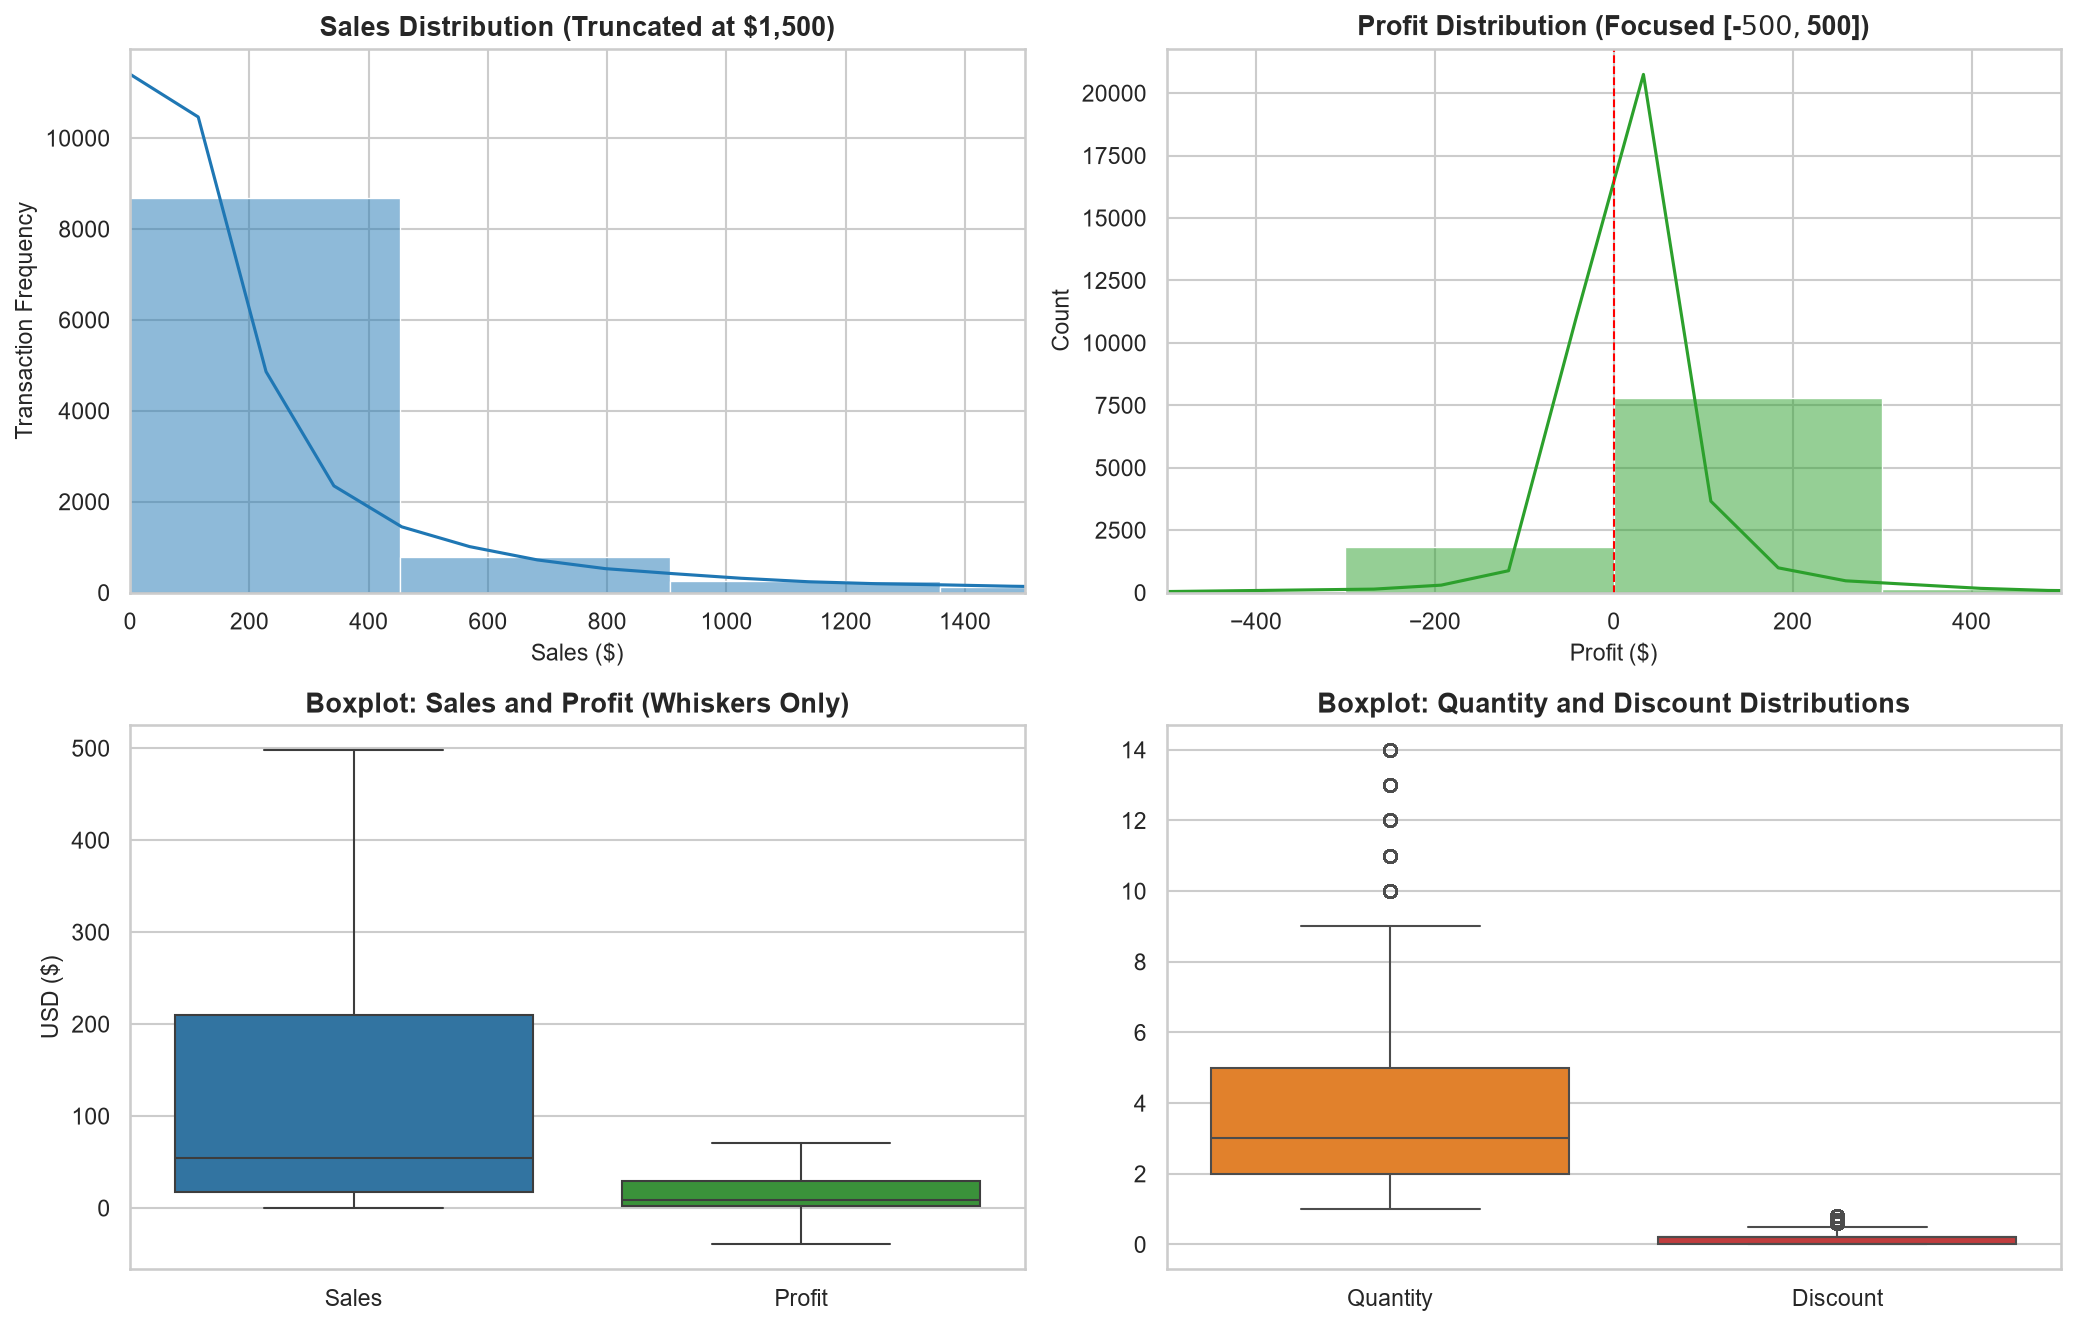

Saved: 01_distributions_and_boxplots.png


In [13]:
# Chart 1: Distributions and Boxplots
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Sales Distribution (Truncated at $1,500 for visual clarity)
sns.histplot(df['Sales'], kde=True, bins=50, ax=axes[0, 0], color='#1f77b4')
axes[0, 0].set_title('Sales Distribution (Truncated at $1,500)')
axes[0, 0].set_xlim(0, 1500)
axes[0, 0].set_xlabel('Sales ($)')
axes[0, 0].set_ylabel('Transaction Frequency')

# 2. Profit Distribution (Focused between -$500 and $500)
sns.histplot(df['Profit'], kde=True, bins=50, ax=axes[0, 1], color='#2ca02c')
axes[0, 1].set_title('Profit Distribution (Focused [-$500, $500])')
axes[0, 1].set_xlim(-500, 500)
axes[0, 1].set_xlabel('Profit ($)')
axes[0, 1].axvline(0, color='red', linestyle='--', linewidth=1)

# 3. Boxplot: Sales and Profit Spread
sns.boxplot(data=df[['Sales', 'Profit']], ax=axes[1, 0], palette=['#1f77b4', '#2ca02c'], showfliers=False)
axes[1, 0].set_title('Boxplot: Sales and Profit (Whiskers Only)')
axes[1, 0].set_ylabel('USD ($)')

# 4. Boxplot: Quantity and Discount Spread
sns.boxplot(data=df[['Quantity', 'Discount']], ax=axes[1, 1], palette=['#ff7f0e', '#d62728'])
axes[1, 1].set_title('Boxplot: Quantity and Discount Distributions')

plt.tight_layout()
chart1_path = reports_dir / '01_distributions_and_boxplots.png'
plt.savefig(chart1_path, bbox_inches='tight')
plt.show()
print(f"Saved: {chart1_path.name}")


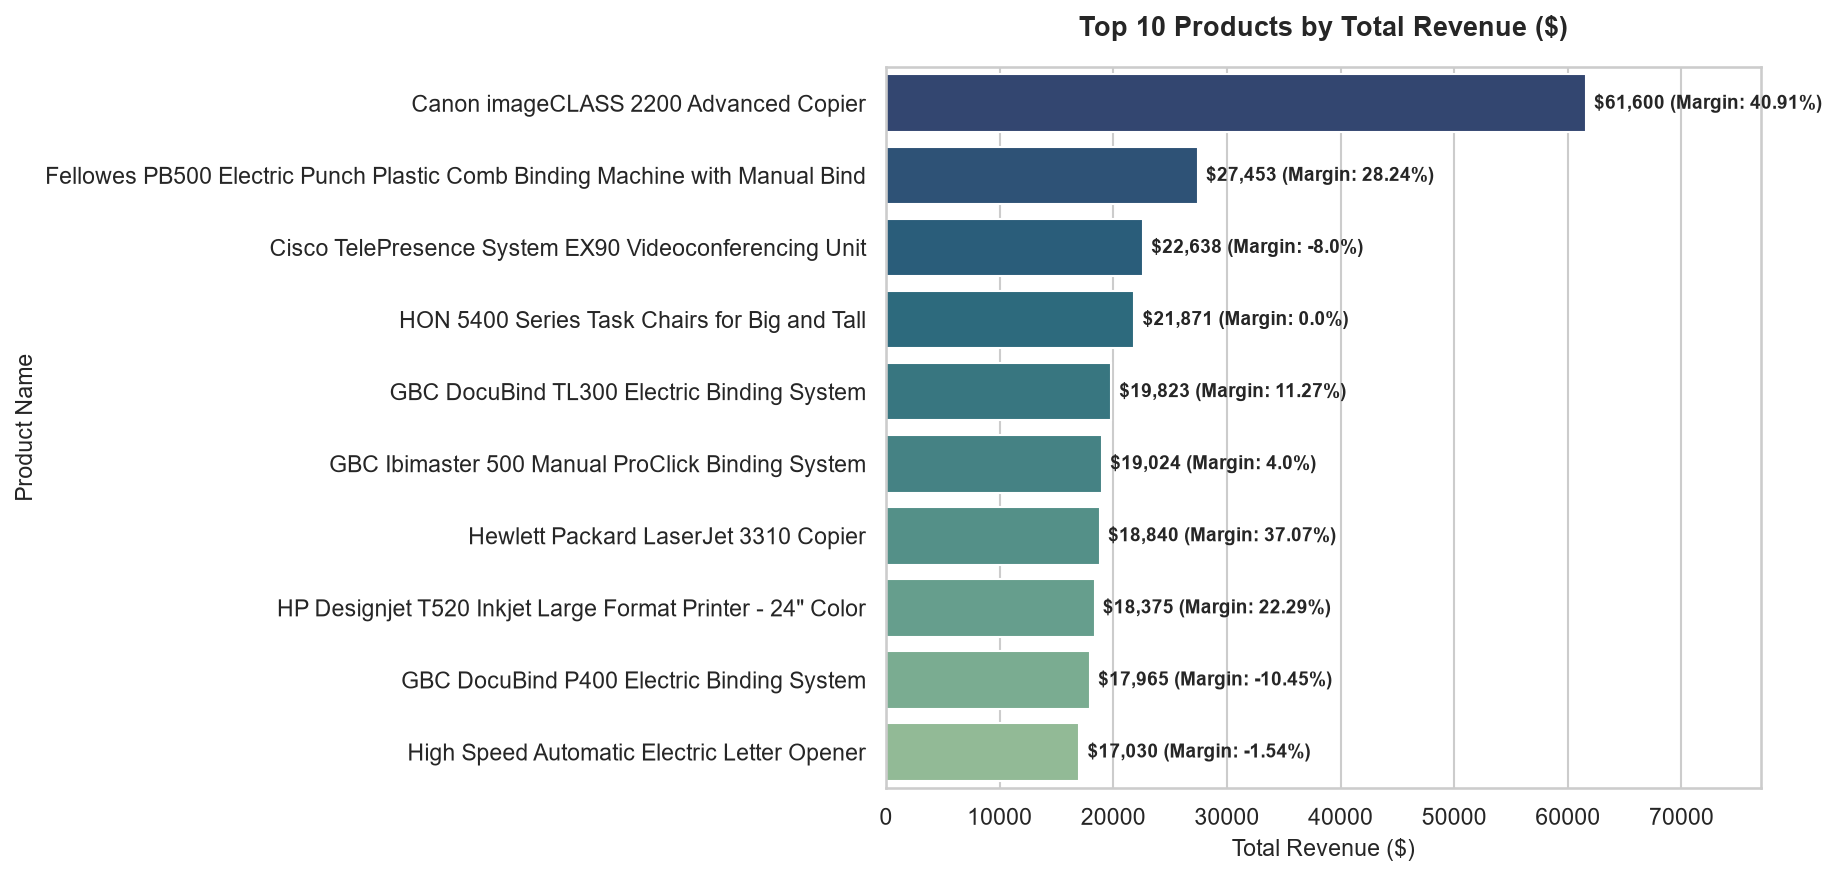

Saved: 02_top_10_products_by_sales.png


In [14]:
# Chart 2: Top 10 Revenue-Generating Products
plt.figure(figsize=(12, 6))
top_plot_df = top10_products.reset_index()

barplot = sns.barplot(
    data=top_plot_df,
    y='Product Name',
    x='Total_Sales',
    palette='crest_r'
)

plt.title('Top 10 Products by Total Revenue ($)', pad=15)
plt.xlabel('Total Revenue ($)')
plt.ylabel('Product Name')

# Add data labels
for i, row in top_plot_df.iterrows():
    plt.text(row['Total_Sales'] + 700, i, f"${row['Total_Sales']:,.0f} (Margin: {row['Profit_Margin_%']}%)", 
             va='center', fontsize=9, weight='bold')

plt.xlim(0, top_plot_df['Total_Sales'].max() * 1.25)
plt.tight_layout()
chart2_path = reports_dir / '02_top_10_products_by_sales.png'
plt.savefig(chart2_path, bbox_inches='tight')
plt.show()
print(f"Saved: {chart2_path.name}")


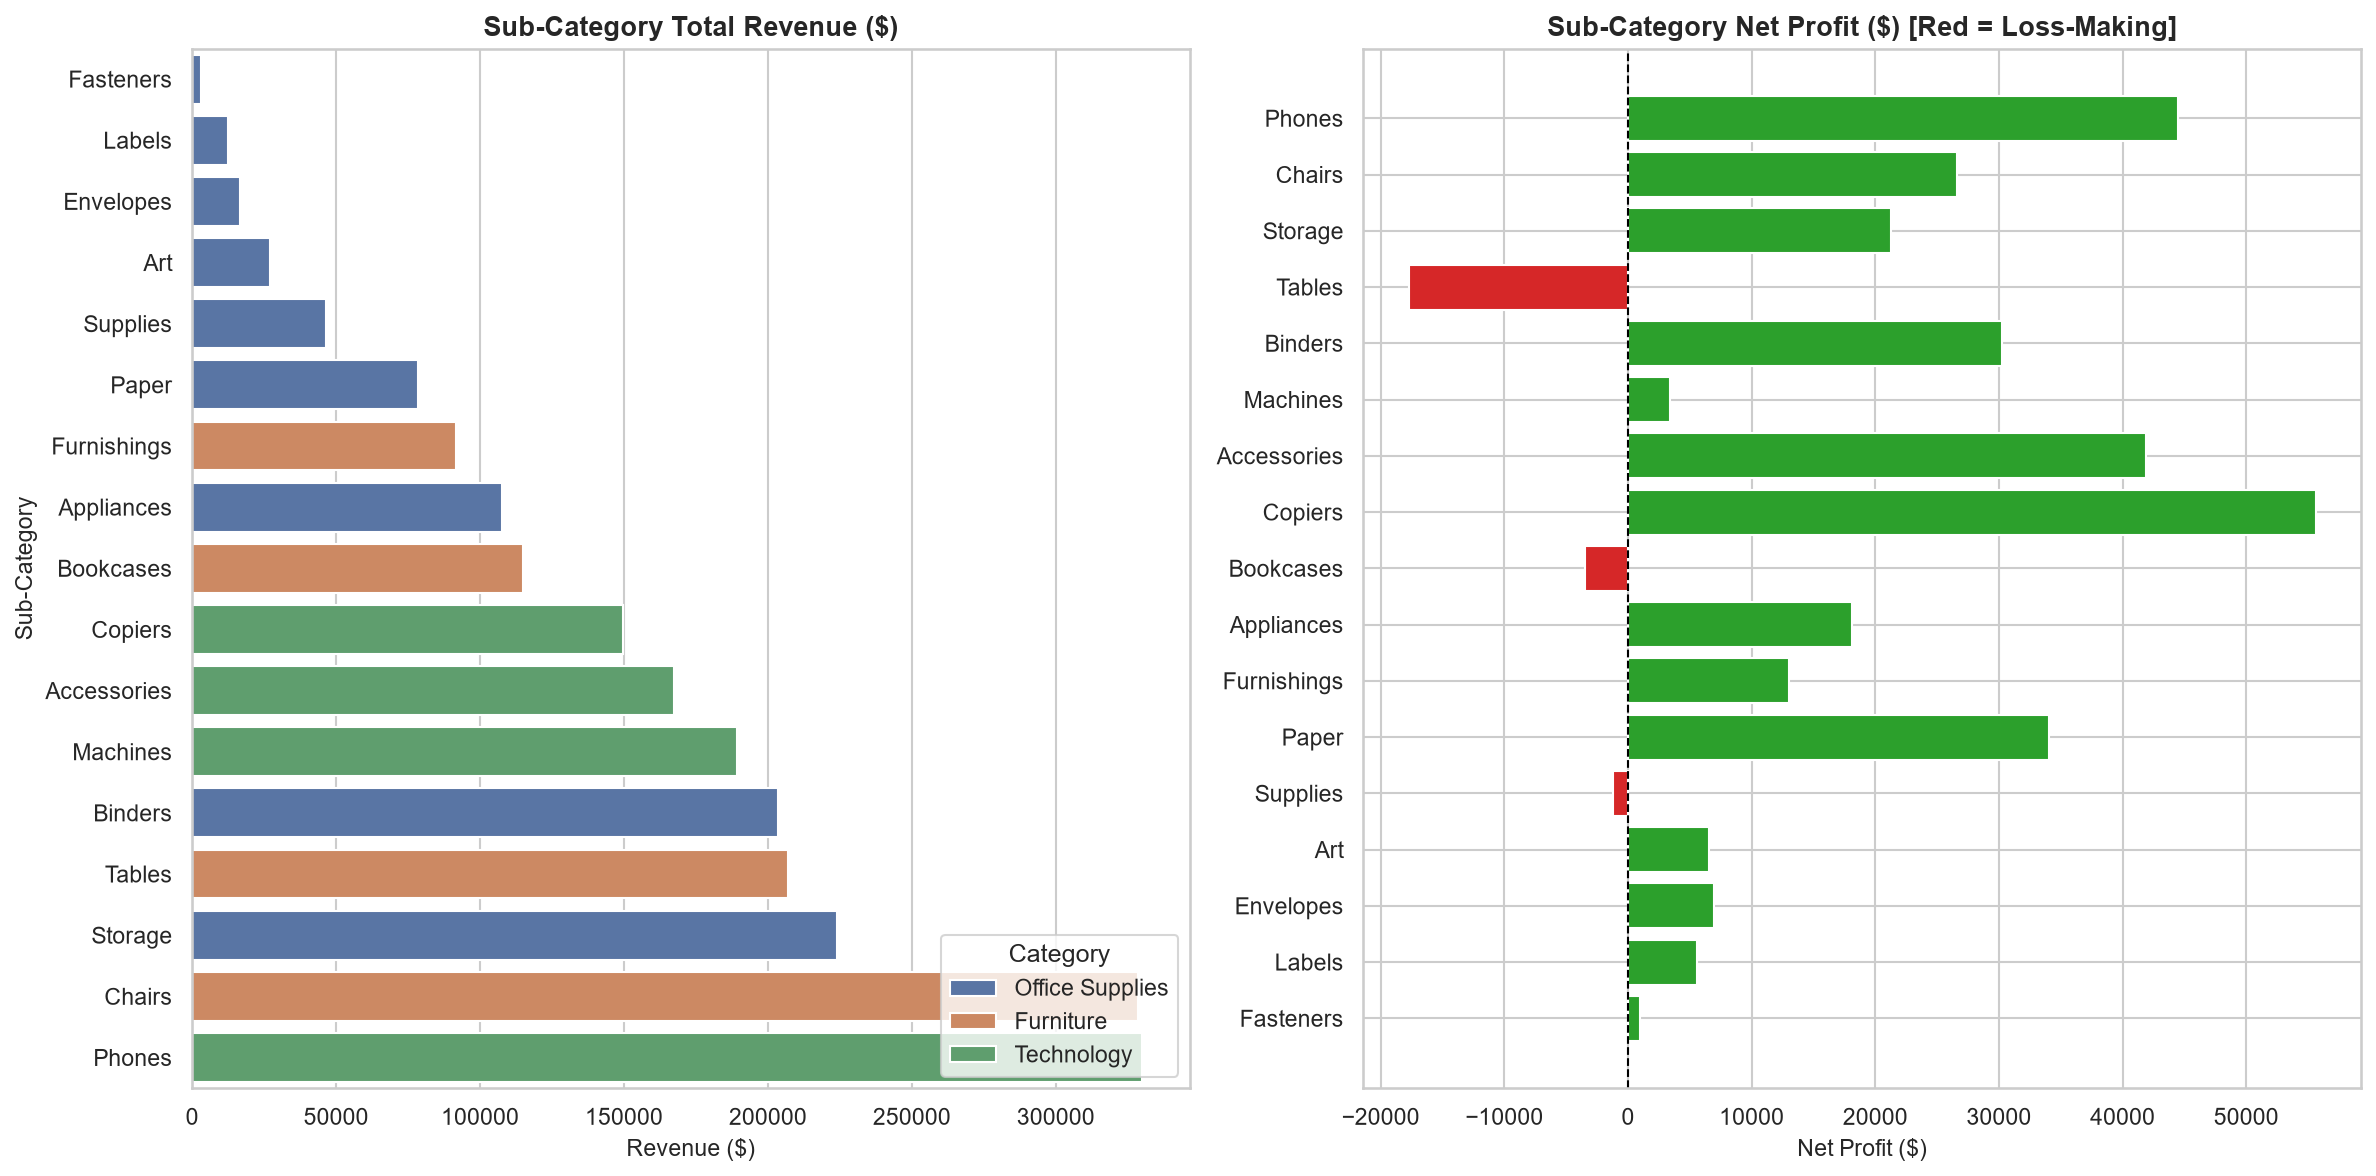

Saved: 03_category_subcategory_performance.png


In [15]:
# Chart 3: Category & Sub-Category Sales and Profit Breakdown
subcat_data = df.groupby(['Category', 'Sub-Category']).agg(
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum')
).reset_index().sort_values(by='Sales', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Sub-Category Total Revenue
sns.barplot(data=subcat_data, y='Sub-Category', x='Sales', hue='Category', dodge=False, ax=axes[0], palette='deep')
axes[0].set_title('Sub-Category Total Revenue ($)')
axes[0].set_xlabel('Revenue ($)')
axes[0].legend(loc='lower right', title='Category')

# Sub-Category Total Profit (Highlighting Negative Sub-Categories)
profit_colors = ['#d62728' if p < 0 else '#2ca02c' for p in subcat_data['Profit']]
axes[1].barh(subcat_data['Sub-Category'], subcat_data['Profit'], color=profit_colors)
axes[1].set_title('Sub-Category Net Profit ($) [Red = Loss-Making]')
axes[1].set_xlabel('Net Profit ($)')
axes[1].axvline(0, color='black', linewidth=1, linestyle='--')

plt.tight_layout()
chart3_path = reports_dir / '03_category_subcategory_performance.png'
plt.savefig(chart3_path, bbox_inches='tight')
plt.show()
print(f"Saved: {chart3_path.name}")


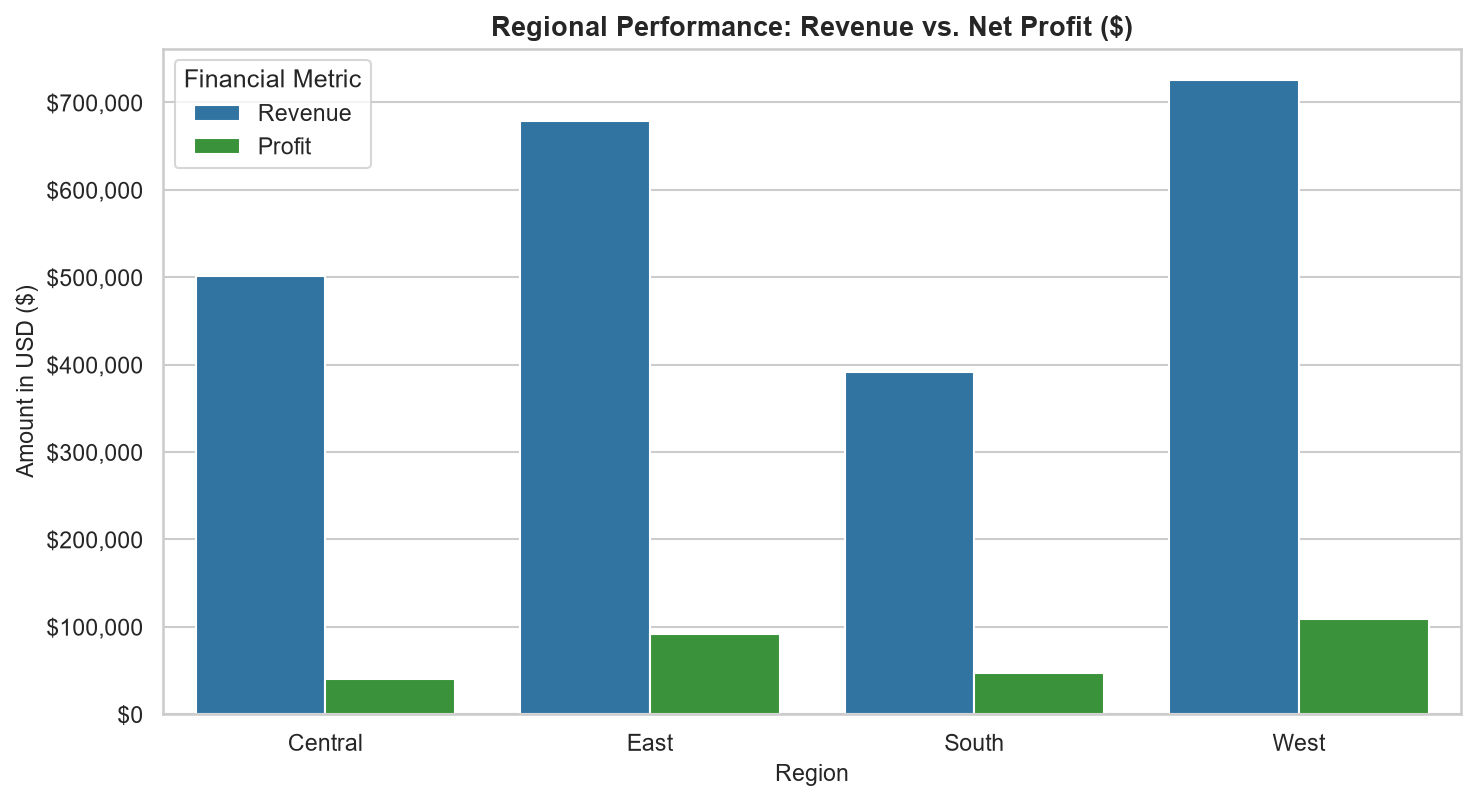

Saved: 04_regional_sales_profit_comparison.png


In [16]:
# Chart 4: Regional Sales vs. Profit Performance
region_plot = df.groupby('Region').agg(
    Revenue=('Sales', 'sum'),
    Profit=('Profit', 'sum')
).reset_index().melt(id_vars='Region', var_name='Financial Metric', value_name='Amount')

plt.figure(figsize=(10, 5.5))
sns.barplot(data=region_plot, x='Region', y='Amount', hue='Financial Metric', palette=['#1f77b4', '#2ca02c'])
plt.title('Regional Performance: Revenue vs. Net Profit ($)')
plt.ylabel('Amount in USD ($)')
plt.xlabel('Region')

# Formatting y-axis ticks in thousands
plt.gca().yaxis.set_major_formatter('${x:,.0f}')
plt.tight_layout()
chart4_path = reports_dir / '04_regional_sales_profit_comparison.png'
plt.savefig(chart4_path, bbox_inches='tight')
plt.show()
print(f"Saved: {chart4_path.name}")


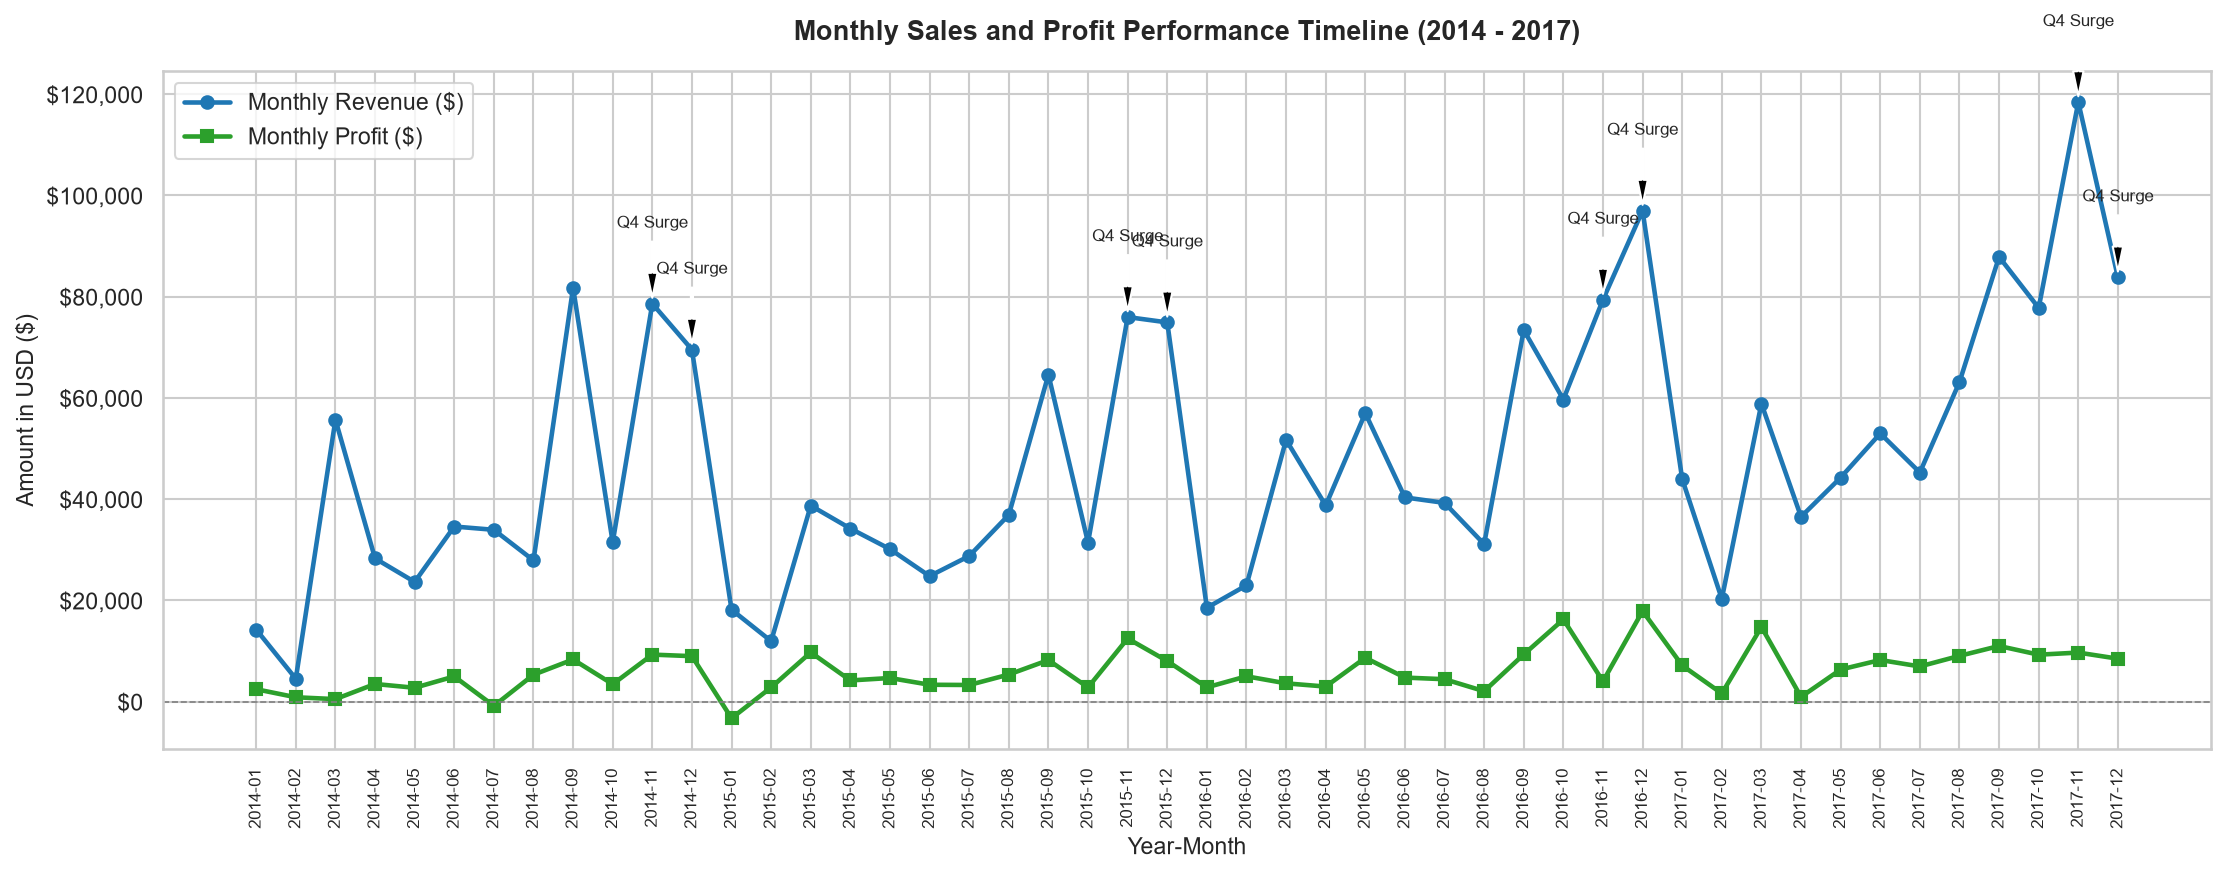

Saved: 05_monthly_sales_trend.png


In [17]:
# Chart 5: Multi-Year Monthly Sales and Profit Trend (2014 - 2017)
plt.figure(figsize=(15, 6))

plt.plot(monthly_trend['Year_Month_Str'], monthly_trend['Sales'], 
         marker='o', color='#1f77b4', linewidth=2.2, label='Monthly Revenue ($)')
plt.plot(monthly_trend['Year_Month_Str'], monthly_trend['Profit'], 
         marker='s', color='#2ca02c', linewidth=2.2, label='Monthly Profit ($)')

plt.title('Monthly Sales and Profit Performance Timeline (2014 - 2017)', pad=15)
plt.xlabel('Year-Month')
plt.ylabel('Amount in USD ($)')
plt.xticks(rotation=90, fontsize=8)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.legend(loc='upper left', frameon=True)
plt.gca().yaxis.set_major_formatter('${x:,.0f}')

# Highlight annual Q4 seasonal peaks
q4_months = [m for m in monthly_trend['Year_Month_Str'] if m.endswith('-11') or m.endswith('-12')]
for q4 in q4_months:
    val = monthly_trend.loc[monthly_trend['Year_Month_Str'] == q4, 'Sales'].values[0]
    plt.annotate('Q4 Surge', xy=(q4, val), xytext=(q4, val + 15000),
                 arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=5),
                 fontsize=8, ha='center')

plt.tight_layout()
chart5_path = reports_dir / '05_monthly_sales_trend.png'
plt.savefig(chart5_path, bbox_inches='tight')
plt.show()
print(f"Saved: {chart5_path.name}")


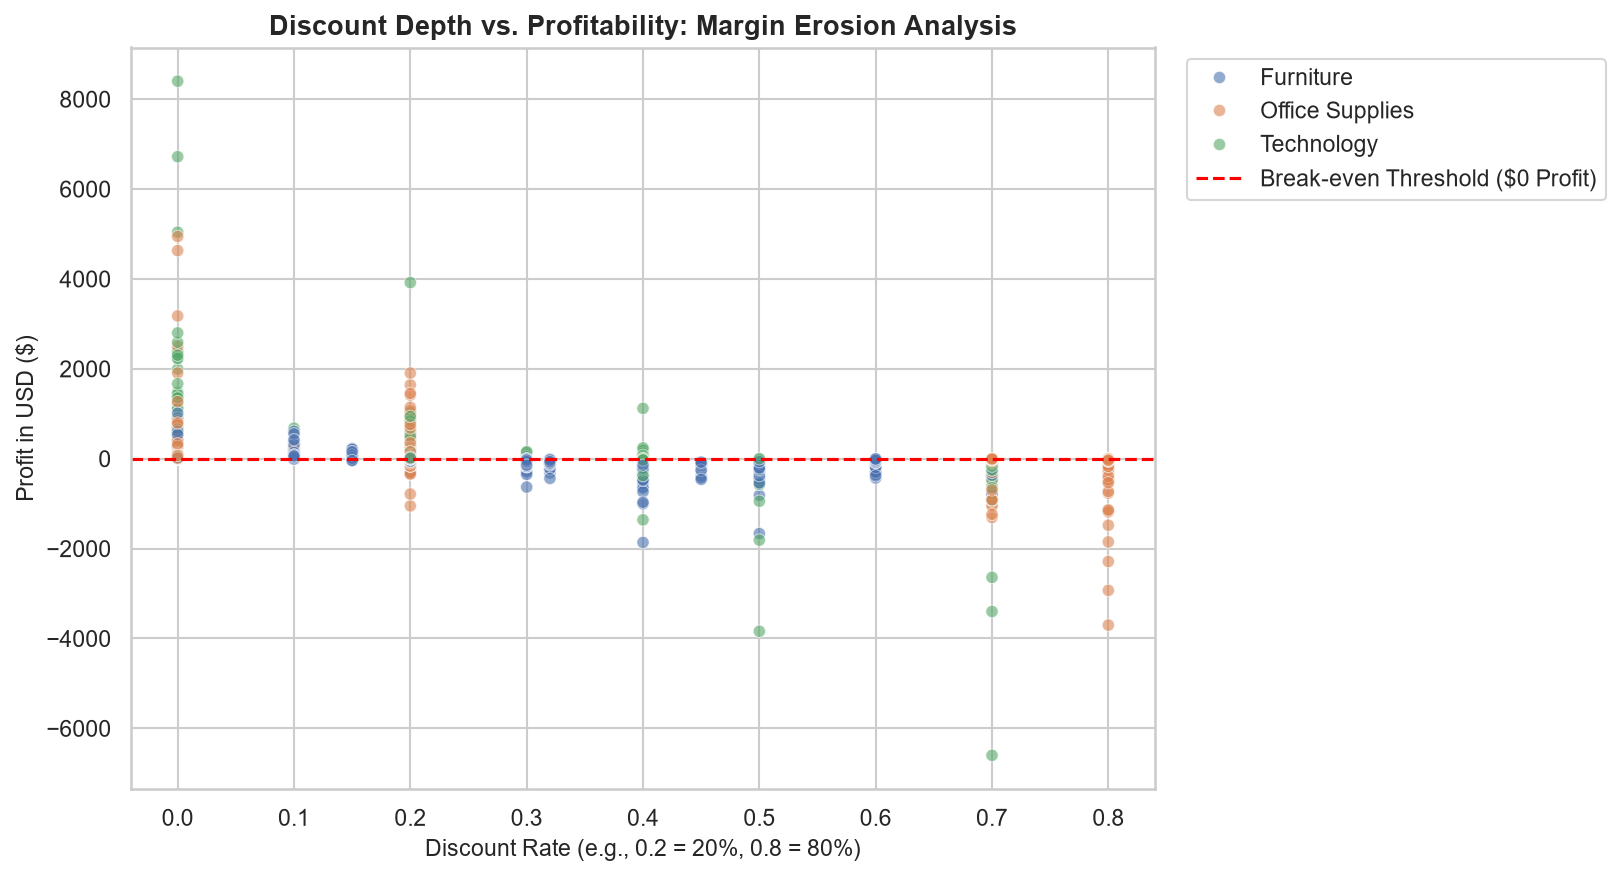

Saved: 06_discount_vs_profit_erosion.png


In [18]:
# Chart 6: Discount Depth vs. Profitability (Margin Erosion Scatter Plot)
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=df,
    x='Discount',
    y='Profit',
    hue='Category',
    alpha=0.6,
    palette='deep',
    s=35
)

plt.axhline(0, color='red', linestyle='--', linewidth=1.5, label='Break-even Threshold ($0 Profit)')
plt.title('Discount Depth vs. Profitability: Margin Erosion Analysis')
plt.xlabel('Discount Rate (e.g., 0.2 = 20%, 0.8 = 80%)')
plt.ylabel('Profit in USD ($)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
chart6_path = reports_dir / '06_discount_vs_profit_erosion.png'
plt.savefig(chart6_path, bbox_inches='tight')
plt.show()
print(f"Saved: {chart6_path.name}")


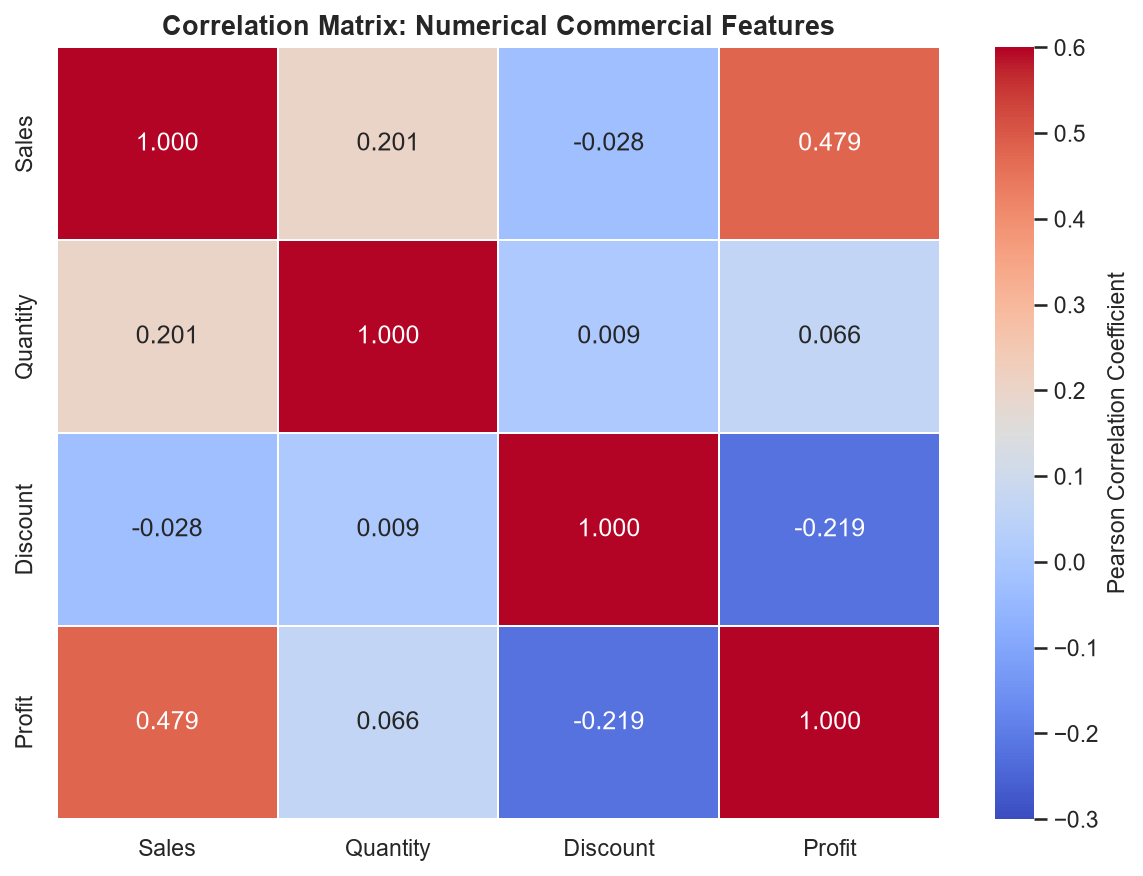

Saved: 07_correlation_heatmap.png


In [19]:
# Chart 7: Numerical Feature Correlation Matrix
plt.figure(figsize=(8, 6))
corr_matrix = df[num_cols].corr()

sns.heatmap(
    corr_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt='.3f', 
    vmin=-0.3, 
    vmax=0.6, 
    linewidths=0.8,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)

plt.title('Correlation Matrix: Numerical Commercial Features')
plt.tight_layout()
chart7_path = reports_dir / '07_correlation_heatmap.png'
plt.savefig(chart7_path, bbox_inches='tight')
plt.show()
print(f"Saved: {chart7_path.name}")


## 10. Key Analytical Findings & Observations

### 1. Data Integrity & Completeness
- **Zero Missing Data:** All 21 columns have a 100% fill rate across 9,994 records.
- **Duplicate Records:** 0 exact full-row duplicates exist. However, **1 business duplicate** is present (`Row ID 3406` and `Row ID 3407` share identical attributes: Order ID `US-2014-150119`, customer, order date, product, and sales value). In Phase 3, this should be addressed during deduplication.
- **Date Formats:** Dates (`Order Date`, `Ship Date`) are stored as strings (`object` dtype) and require casting to standardized `datetime64[ns]` in ETL.

### 2. Commercial & Profitability Dynamics
- **Net Revenue & Margins:** Total revenue is **$2,297,200.86** with an operating profit of **$286,397.02** (overall margin: **12.47%**).
- **Loss-Making Orders:** 1,871 transactions (**18.72%**) resulted in negative profit, generating a cumulative loss of **-$156,131.29**.
- **Discount Erosion:** There is a moderate negative correlation between Discount and Profit ($r = -0.220$). Transactions with discounts exceeding 20% overwhelmingly generate negative profits.
- **Category Profit Disparities:**
  - **Technology:** Leading margin generator (**$145,454.95** profit, **17.40%** margin).
  - **Office Supplies:** Consistent performer (**$122,490.80** profit, **17.04%** margin).
  - **Furniture:** High revenue (**$741,999.80**) but severely compressed margin (**$18,451.27** profit, **2.49%** margin), driven by severe losses in Tables (-$17,725.48) and Bookcases (-$3,472.56).

### 3. Geographical & Temporal Patterns
- **Regional Hierarchy:** The **West** ($725,457.82 revenue, $108,418.45 profit) and **East** ($678,781.24 revenue, $91,522.78 profit) drive 61% of total enterprise revenue and 70% of profit. Central and South lag in profitability due to high average discounts.
- **Strong Q4 Seasonality:** Distinct cyclical spikes occur every November and December, consistent with holiday retail demand.

### 4. Statistical Distributions & Outliers
- **Skewness:** Both `Sales` (skew = 12.97) and `Profit` (skew = 7.57) exhibit heavy right skewness, with maximum values of $22,638.48 (Sales) and $8,399.98 (Profit).
- **Outlier Volume:** Using the 1.5 $	imes$ IQR rule, 1,167 records (11.68%) in Sales and 1,881 records (18.82%) in Profit lie beyond the quartile fences. These represent high-value enterprise bulk purchases rather than measurement errors.
